# Day 5 – Hourly Demand Forecasting
## Uber Eats Operational & Customer Intelligence System

**Objective:** Forecast hourly order demand, analyze trend and seasonality, test stationarity, and compare a seasonal-naive baseline, ARIMA, and Prophet when available.

**Deliverables:** hourly demand dataset, decomposition, ADF results, forecasts, model comparison (MAE/RMSE/MAPE), forecast plots, and a business interpretation.

> This project uses synthetic data. Run from the project's `notebooks/` folder. Time-series validation is chronological; observations are not randomly shuffled.

## 1. Imports and project paths

In [2]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.arima.model import ARIMA

PROJECT_ROOT = Path("..").resolve()
DATA_DIR = PROJECT_ROOT / "data" / "synthetic"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIGURE_DIR = PROJECT_ROOT / "reports" / "figures"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
print("Project:", PROJECT_ROOT)
print("CSV files:", [p.name for p in DATA_DIR.glob("*.csv")])

Project: /home/nineleaps/uber-eats-intelligence
CSV files: ['reviews.csv', 'customers.csv', 'restaurants.csv', 'orders.csv', 'deliveries.csv', 'drivers.csv', 'payments.csv']


## 2. Load orders and inspect columns

In [3]:
orders_path = DATA_DIR / "orders.csv"
if not orders_path.exists():
    raise FileNotFoundError(f"Missing {orders_path}; check that orders.csv is in data/synthetic/.")
orders = pd.read_csv(orders_path)
print("Shape:", orders.shape)
print("Columns:", orders.columns.tolist())
display(orders.head())

Shape: (10000, 14)
Columns: ['order_id', 'customer_id', 'restaurant_id', 'order_timestamp', 'order_amount', 'number_of_items', 'delivery_distance_km', 'prep_time_minutes', 'delivery_time_minutes', 'traffic', 'weather', 'is_weekend', 'peak_period_weight', 'order_status']


,order_id,customer_id,restaurant_id,order_timestamp,order_amount,number_of_items,delivery_distance_km,prep_time_minutes,delivery_time_minutes,traffic,weather,is_weekend,peak_period_weight,order_status
0,O00001,C0568,R064,2026-01-22 21:53:00,453.07,3,2.73,19,38,Medium,Clear,0,1.2,Delivered
1,O00002,C0500,R074,2026-06-24 20:16:00,357.08,2,3.09,15,40,Medium,Clear,0,1.2,Delivered
2,O00003,C0746,R084,2026-04-03 03:15:00,1100.53,1,5.07,36,56,Medium,Clear,0,1.0,Delivered
3,O00004,C0749,R100,2026-04-10 13:00:00,509.76,7,3.84,11,30,Low,Cloudy,0,1.2,Delivered
4,O00005,C0017,R019,2026-03-16 11:02:00,659.16,6,3.16,27,58,High,Clear,0,1.0,Delivered


## 3. Detect timestamp and build hourly demand

In [4]:
def norm(s):
    return "".join(ch.lower() for ch in str(s) if ch.isalnum())

def find_col(frame, candidates):
    lookup = {norm(c): c for c in frame.columns}
    for cand in candidates:
        if norm(cand) in lookup:
            return lookup[norm(cand)]
    for cand in candidates:
        for key, original in lookup.items():
            if norm(cand) and (norm(cand) in key or key in norm(cand)):
                return original
    return None

timestamp_col = find_col(orders, [
    "order_timestamp", "order_datetime", "order_time", "created_at",
    "order_date", "placed_at", "created_time", "timestamp"
])
if timestamp_col is None:
    raise ValueError("Timestamp column not detected. Inspect orders.columns and add its exact name to timestamp candidates.")

orders[timestamp_col] = pd.to_datetime(orders[timestamp_col], errors="coerce")
orders = orders.dropna(subset=[timestamp_col]).copy()
if orders.empty:
    raise ValueError(f"No valid timestamps in {timestamp_col!r}.")

orders["hour"] = orders[timestamp_col].dt.floor("h")
hourly = orders.groupby("hour").size().rename("order_count").to_frame()
hourly = hourly.asfreq("h", fill_value=0).astype(float)
hourly.index.name = "timestamp"
series = hourly["order_count"]
hourly.to_csv(PROCESSED_DIR / "day5_hourly_demand.csv")
print("Timestamp column:", timestamp_col)
print("Time range:", series.index.min(), "to", series.index.max())
print("Hourly rows:", len(series), "| zero-order hours:", int((series == 0).sum()))
display(hourly.head())
display(series.describe())

Timestamp column: order_timestamp
Time range: 2026-01-01 01:00:00 to 2026-06-29 23:00:00
Hourly rows: 4319 | zero-order hours: 416


,order_count
timestamp,
2026-01-01 01:00:00,3.0
2026-01-01 02:00:00,1.0
2026-01-01 03:00:00,0.0
2026-01-01 04:00:00,5.0
2026-01-01 05:00:00,3.0


count    4319.000000
mean        2.315351
std         1.502699
min         0.000000
25%         1.000000
50%         2.000000
75%         3.000000
max         9.000000
Name: order_count, dtype: float64

## 4. EDA: demand over time and by hour

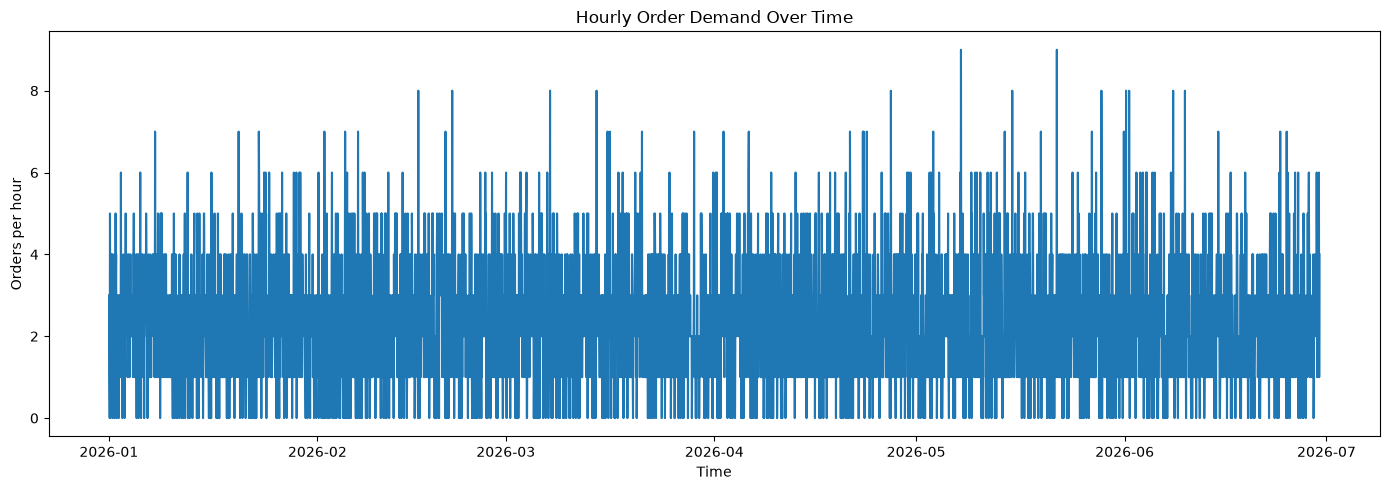

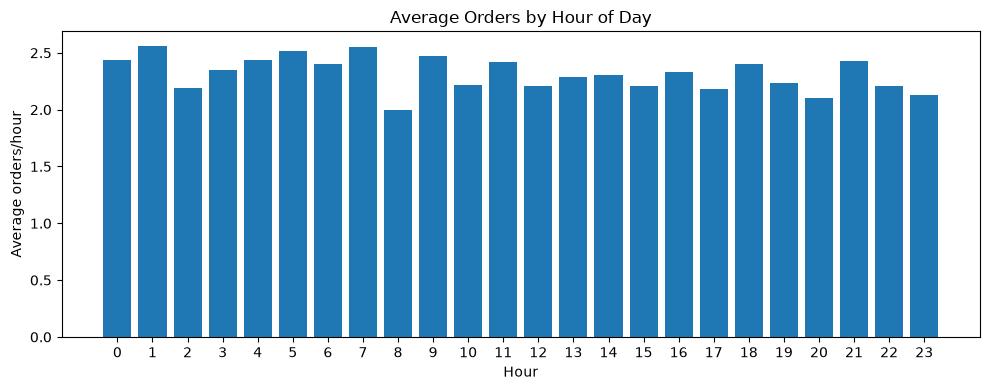

Peak average-demand hour: 1 :00
Peak-hour average: 2.561


In [5]:
plt.figure(figsize=(14, 5))
plt.plot(series.index, series.values)
plt.title("Hourly Order Demand Over Time")
plt.xlabel("Time"); plt.ylabel("Orders per hour"); plt.tight_layout()
plt.savefig(FIGURE_DIR / "day5_hourly_demand_timeseries.png", dpi=150); plt.show()

hourly["hour_of_day"] = hourly.index.hour
hourly["day_of_week"] = hourly.index.dayofweek
hourly["day_name"] = hourly.index.day_name()
hourly["is_weekend"] = hourly.index.dayofweek >= 5
avg_hour = hourly.groupby("hour_of_day")["order_count"].mean()
plt.figure(figsize=(10, 4))
plt.bar(avg_hour.index, avg_hour.values)
plt.title("Average Orders by Hour of Day")
plt.xlabel("Hour"); plt.ylabel("Average orders/hour"); plt.xticks(range(24))
plt.tight_layout(); plt.savefig(FIGURE_DIR / "day5_average_orders_by_hour.png", dpi=150); plt.show()
print("Peak average-demand hour:", int(avg_hour.idxmax()), ":00")
print("Peak-hour average:", round(float(avg_hour.max()), 3))

## 5. Daily, weekday/weekend and peak-demand patterns

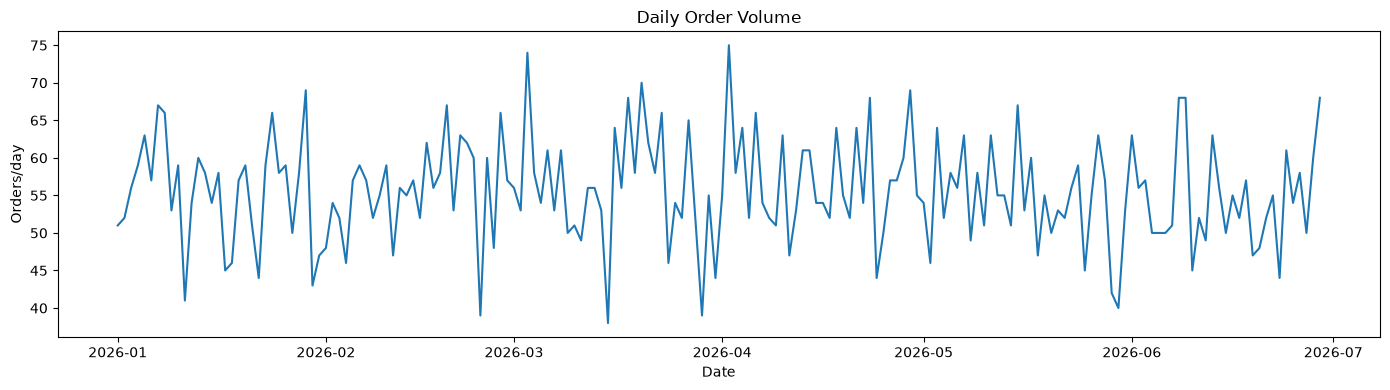

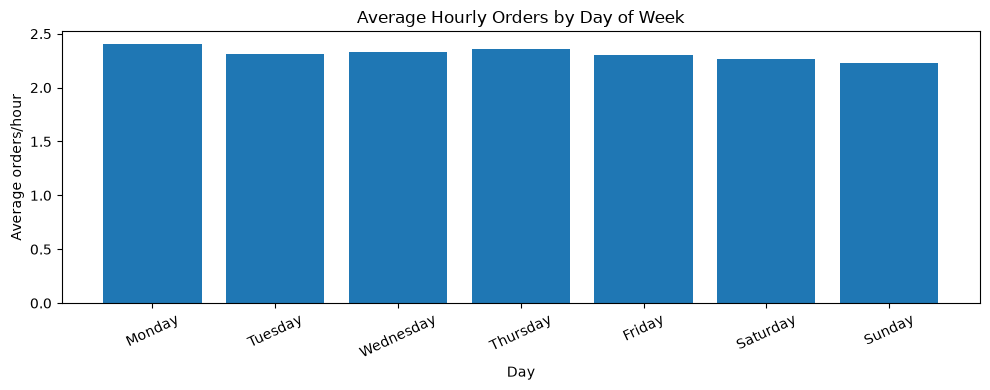

,mean,median,sum,count
is_weekend,,,,
False,2.341583,2.0,7191.0,3071
True,2.250801,2.0,2809.0,1248


,average_orders
day_name,
Monday,2.402244
Tuesday,2.313333
Wednesday,2.328333
Thursday,2.362761
Friday,2.299679
Saturday,2.269231
Sunday,2.232372


,average_orders
hour_of_day,
1,2.561111
7,2.550000
5,2.516667
9,2.472222
0,2.435754


In [6]:
daily = series.resample("D").sum().rename("daily_orders")
plt.figure(figsize=(14, 4))
plt.plot(daily.index, daily.values)
plt.title("Daily Order Volume"); plt.xlabel("Date"); plt.ylabel("Orders/day")
plt.tight_layout(); plt.savefig(FIGURE_DIR / "day5_daily_demand.png", dpi=150); plt.show()

day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
avg_day = hourly.groupby("day_name")["order_count"].mean().reindex(day_order).dropna()
plt.figure(figsize=(10, 4))
plt.bar(avg_day.index, avg_day.values)
plt.title("Average Hourly Orders by Day of Week")
plt.xlabel("Day"); plt.ylabel("Average orders/hour"); plt.xticks(rotation=25)
plt.tight_layout(); plt.savefig(FIGURE_DIR / "day5_average_orders_by_weekday.png", dpi=150); plt.show()

weekend = hourly.groupby("is_weekend")["order_count"].agg(["mean", "median", "sum", "count"])
display(weekend)
display(avg_day.rename("average_orders").to_frame())
display(avg_hour.sort_values(ascending=False).head(5).rename("average_orders").to_frame())
avg_day.to_csv(PROCESSED_DIR / "day5_average_demand_by_weekday.csv")
weekend.to_csv(PROCESSED_DIR / "day5_weekend_comparison.csv")

## 6. Time-series decomposition

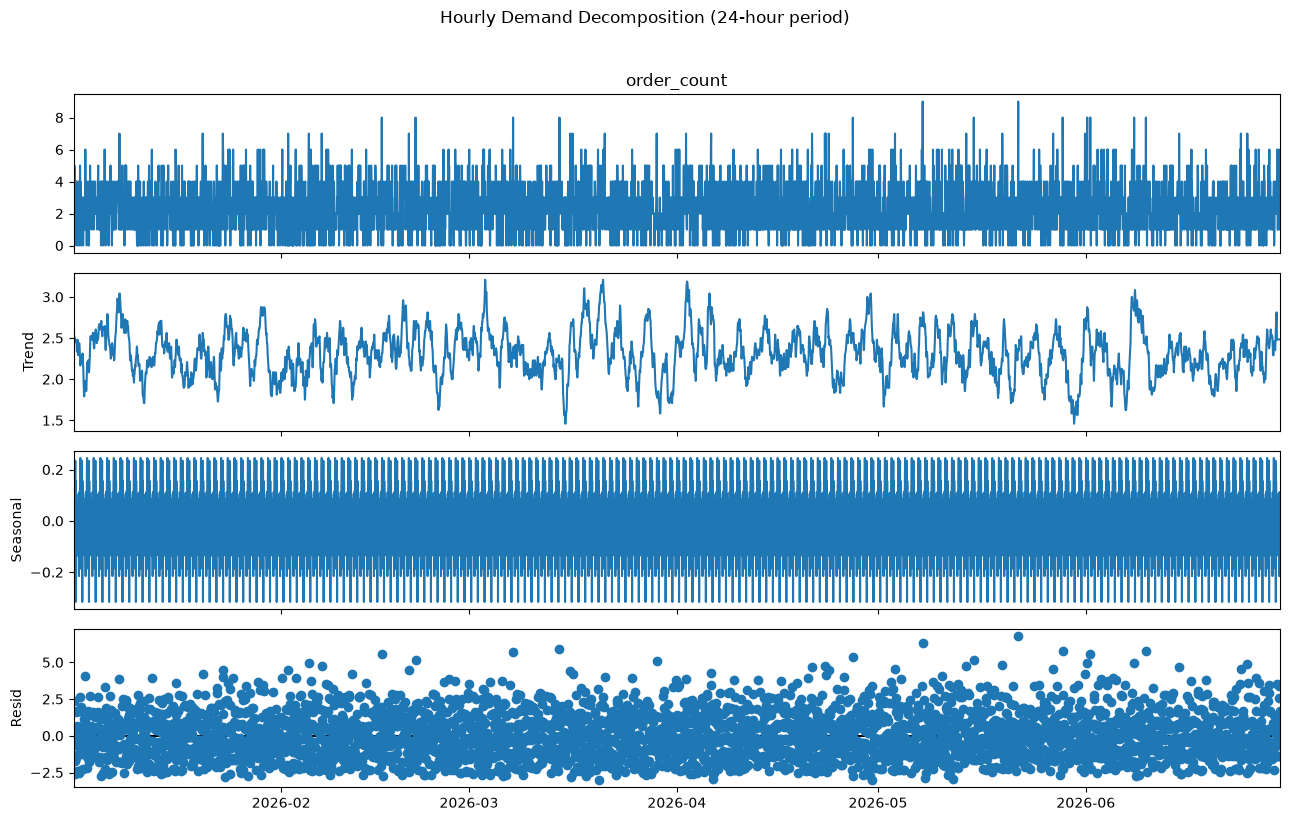

In [7]:
if len(series) >= 48:
    try:
        decomposition = seasonal_decompose(series, model="additive", period=24, extrapolate_trend="freq")
        fig = decomposition.plot()
        fig.set_size_inches(13, 8)
        fig.suptitle("Hourly Demand Decomposition (24-hour period)", y=1.02)
        plt.tight_layout()
        plt.savefig(FIGURE_DIR / "day5_time_series_decomposition.png", dpi=150, bbox_inches="tight")
        plt.show()
    except Exception as e:
        print("Decomposition failed:", e)
else:
    print("Need at least 48 hourly observations for a 24-hour decomposition.")

## 7. ADF stationarity test and differencing

In [8]:
def adf_row(values, label):
    values = pd.Series(values).dropna()
    if len(values) < 10 or values.nunique() <= 1:
        print(label, ": insufficient variation/observations")
        return None
    result = adfuller(values, autolag="AIC")
    row = {
        "series": label, "adf_statistic": result[0], "p_value": result[1],
        "used_lags": result[2], "observations": result[3],
        "critical_1_percent": result[4]["1%"],
        "critical_5_percent": result[4]["5%"],
        "critical_10_percent": result[4]["10%"]
    }
    print(f"{label}: ADF={result[0]:.4f}, p-value={result[1]:.4f}")
    return row

adf_rows = []
r = adf_row(series, "Original hourly demand")
if r: adf_rows.append(r)
r = adf_row(series.diff(), "First-differenced hourly demand")
if r: adf_rows.append(r)
adf_table = pd.DataFrame(adf_rows)
display(adf_table)
adf_table.to_csv(PROCESSED_DIR / "day5_adf_test_results.csv", index=False)

Original hourly demand: ADF=-35.0147, p-value=0.0000
First-differenced hourly demand: ADF=-19.9802, p-value=0.0000


,series,adf_statistic,p_value,used_lags,observations,critical_1_percent,critical_5_percent,critical_10_percent
0,Original hourly demand,-35.014651,0.0,3,4315,-3.431866,-2.862210,-2.567127
1,First-differenced hourly demand,-19.980243,0.0,31,4286,-3.431877,-2.862215,-2.567129


## 8. Chronological train/test split

Train: 2026-01-01 01:00:00 to 2026-05-24 23:00:00 (3455 rows)
Test: 2026-05-25 00:00:00 to 2026-06-29 23:00:00 (864 rows)


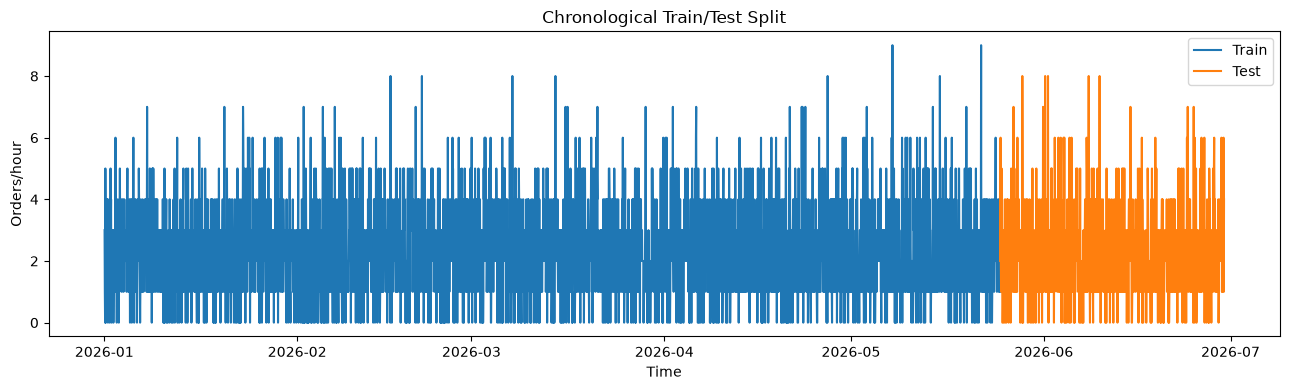

In [9]:
if len(series) < 30:
    raise ValueError(f"Only {len(series)} hourly observations; need more for a meaningful forecast comparison.")
split_idx = int(len(series) * 0.80)
train, test = series.iloc[:split_idx], series.iloc[split_idx:]
print("Train:", train.index.min(), "to", train.index.max(), f"({len(train)} rows)")
print("Test:", test.index.min(), "to", test.index.max(), f"({len(test)} rows)")
plt.figure(figsize=(13, 4))
plt.plot(train.index, train, label="Train")
plt.plot(test.index, test, label="Test")
plt.title("Chronological Train/Test Split"); plt.xlabel("Time"); plt.ylabel("Orders/hour")
plt.legend(); plt.tight_layout()
plt.savefig(FIGURE_DIR / "day5_train_test_split.png", dpi=150); plt.show()

## 9. Seasonal-naive baseline

In [10]:
def seasonal_naive(train_series, horizon, period=24, forecast_index=None):
    if len(train_series) >= period:
        vals = np.resize(train_series.iloc[-period:].to_numpy(), horizon)
    else:
        vals = np.repeat(float(train_series.iloc[-1]), horizon)
    return pd.Series(vals, index=forecast_index)

baseline_pred = seasonal_naive(train, len(test), 24, test.index)

## 10. ARIMA model

In [11]:
p_original = None
if not adf_table.empty:
    row = adf_table.loc[adf_table["series"] == "Original hourly demand", "p_value"]
    if len(row): p_original = float(row.iloc[0])
d_order = 0 if p_original is not None and p_original < 0.05 else 1
arima_order = (1, d_order, 1)
arima_pred = None
print("ARIMA order:", arima_order)
try:
    arima_fit = ARIMA(train, order=arima_order).fit()
    arima_pred = pd.Series(np.asarray(arima_fit.forecast(steps=len(test))), index=test.index)
    print(arima_fit.summary())
except Exception as e:
    print("ARIMA fitting failed:", e)

ARIMA order: (1, 0, 1)
                               SARIMAX Results                                
Dep. Variable:            order_count   No. Observations:                 3455
Model:                 ARIMA(1, 0, 1)   Log Likelihood               -6301.771
Date:                Thu, 29 Oct 2026   AIC                          12611.542
Time:                        15:12:32   BIC                          12636.132
Sample:                    01-01-2026   HQIC                         12620.324
                         - 05-24-2026                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          2.3317      0.023    100.317      0.000       2.286       2.377
ar.L1          0.8907      0.087     10.184      0.000       0.719       1.062
ma.L1         -0.9079      0.

## 11. Prophet model (optional)

In [12]:
prophet_pred = None
prophet_status = "Not run"
try:
    from prophet import Prophet
    prophet_train = pd.DataFrame({"ds": train.index, "y": train.values})
    prophet_model = Prophet(daily_seasonality=True, weekly_seasonality=True, yearly_seasonality=False)
    prophet_model.fit(prophet_train)
    future = pd.DataFrame({"ds": test.index})
    prophet_fc = prophet_model.predict(future)
    prophet_pred = pd.Series(prophet_fc["yhat"].to_numpy(), index=test.index).clip(lower=0)
    prophet_status = "Success"
    print("Prophet fit completed.")
except ImportError:
    prophet_status = "Skipped: Prophet is not installed"
    print(prophet_status)
except Exception as e:
    prophet_status = f"Failed: {e}"
    print("Prophet failed:", e)

Skipped: Prophet is not installed


## 12. Evaluate models using MAE, RMSE and MAPE

In [13]:
def metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    nonzero = actual != 0
    mape = np.mean(np.abs((actual[nonzero] - predicted[nonzero]) / actual[nonzero])) * 100 if nonzero.any() else np.nan
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "MAPE_percent_nonzero_actuals": mape
    }

forecast_map = {"Seasonal Naive Baseline": baseline_pred}
if arima_pred is not None: forecast_map[f"ARIMA{arima_order}"] = arima_pred
if prophet_pred is not None: forecast_map["Prophet"] = prophet_pred

comparison = pd.DataFrame([
    {"Model": name, **metrics(test, pred)} for name, pred in forecast_map.items()
]).sort_values("MAE").reset_index(drop=True)
display(comparison.round(4))
comparison.to_csv(PROCESSED_DIR / "day5_forecast_model_comparison.csv", index=False)
best_name = comparison.iloc[0]["Model"]
best_pred = forecast_map[best_name]
print("Best model by test MAE:", best_name)

,Model,MAE,RMSE,MAPE_percent_nonzero_actuals
0,"ARIMA(1, 0, 1)",1.2047,1.5114,56.8263
1,Seasonal Naive Baseline,1.4907,1.9484,73.2205


Best model by test MAE: ARIMA(1, 0, 1)


## 13. Forecast comparison plot and saved test predictions

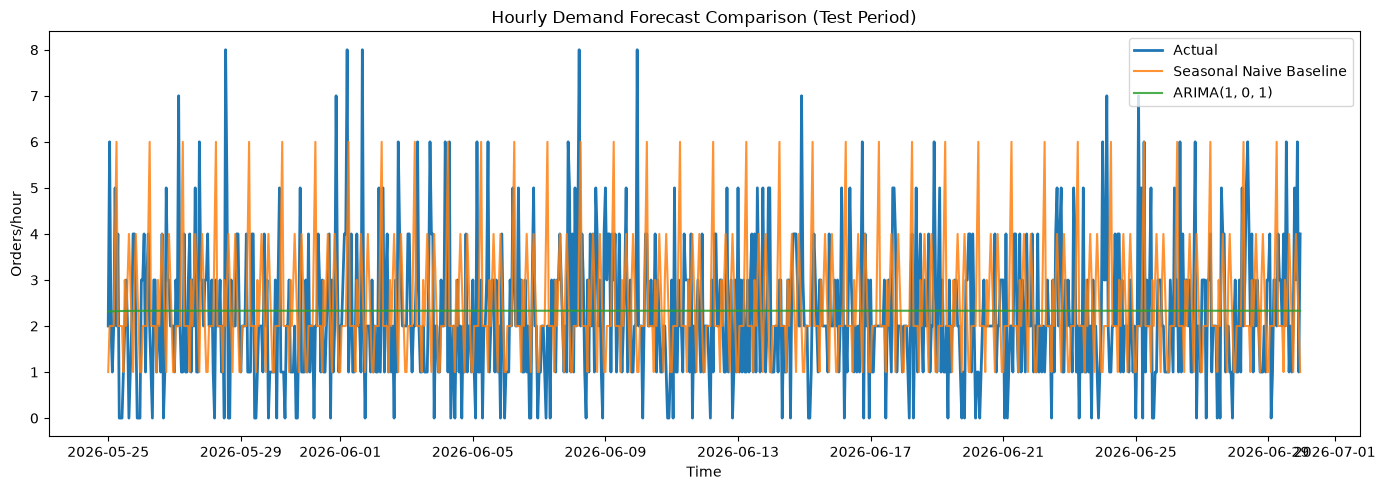

In [14]:
plt.figure(figsize=(14, 5))
plt.plot(test.index, test.values, label="Actual", linewidth=2)
for name, pred in forecast_map.items():
    plt.plot(pred.index, pred.values, label=name, alpha=0.85)
plt.title("Hourly Demand Forecast Comparison (Test Period)")
plt.xlabel("Time"); plt.ylabel("Orders/hour"); plt.legend(); plt.tight_layout()
plt.savefig(FIGURE_DIR / "day5_forecast_comparison.png", dpi=150); plt.show()

forecast_output = pd.DataFrame({"actual_orders": test})
for name, pred in forecast_map.items():
    forecast_output[name] = pred
forecast_output.to_csv(PROCESSED_DIR / "day5_test_forecasts.csv", index_label="timestamp")

## 14. Forecast the next 24 hours using the selected model

,forecast_orders
2026-06-30 00:00:00,2.22
2026-06-30 01:00:00,2.23
2026-06-30 02:00:00,2.25
2026-06-30 03:00:00,2.26
2026-06-30 04:00:00,2.26
2026-06-30 05:00:00,2.27
2026-06-30 06:00:00,2.28
2026-06-30 07:00:00,2.28
2026-06-30 08:00:00,2.29
2026-06-30 09:00:00,2.29


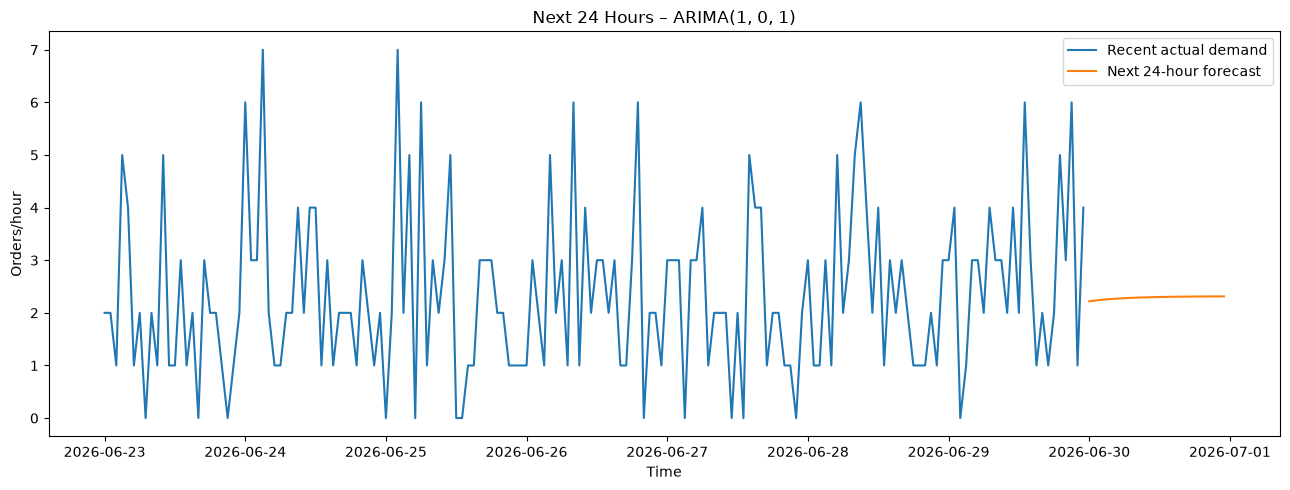

In [15]:
horizon = 24
future_index = pd.date_range(series.index[-1] + pd.Timedelta(hours=1), periods=horizon, freq="h")
try:
    if best_name.startswith("ARIMA"):
        final_fit = ARIMA(series, order=arima_order).fit()
        values = np.asarray(final_fit.forecast(steps=horizon))
        future_forecast = pd.Series(np.maximum(values, 0), index=future_index, name="forecast_orders")
    elif best_name == "Prophet":
        from prophet import Prophet
        final_model = Prophet(daily_seasonality=True, weekly_seasonality=True, yearly_seasonality=False)
        final_model.fit(pd.DataFrame({"ds": series.index, "y": series.values}))
        future_df = pd.DataFrame({"ds": future_index})
        pred_df = final_model.predict(future_df)
        future_forecast = pd.Series(np.maximum(pred_df["yhat"].to_numpy(), 0), index=future_index, name="forecast_orders")
    else:
        values = np.resize(series.iloc[-min(24, len(series)):].to_numpy(), horizon)
        future_forecast = pd.Series(values, index=future_index, name="forecast_orders")
except Exception as e:
    print("Refit failed; falling back to seasonal-naive forecast:", e)
    values = np.resize(series.iloc[-min(24, len(series)):].to_numpy(), horizon)
    future_forecast = pd.Series(values, index=future_index, name="forecast_orders")

future_forecast = future_forecast.clip(lower=0)
display(future_forecast.to_frame().round(2))
future_forecast.to_frame().to_csv(PROCESSED_DIR / "day5_next_24_hour_forecast.csv")
recent = series.iloc[-min(7*24, len(series)):]
plt.figure(figsize=(13, 5))
plt.plot(recent.index, recent.values, label="Recent actual demand")
plt.plot(future_forecast.index, future_forecast.values, label="Next 24-hour forecast")
plt.title(f"Next 24 Hours – {best_name}"); plt.xlabel("Time"); plt.ylabel("Orders/hour")
plt.legend(); plt.tight_layout()
plt.savefig(FIGURE_DIR / "day5_next_24_hour_forecast.png", dpi=150); plt.show()

## 15. Save the evaluation report

In [16]:
peak_hour = int(avg_hour.idxmax())
peak_avg = float(avg_hour.max())
best_row = comparison.loc[comparison["Model"] == best_name].iloc[0]
report = [
    "# Day 5 – Hourly Demand Forecasting Report", "",
    "## Data preparation",
    f"- Source: `data/synthetic/orders.csv`",
    f"- Timestamp column: `{timestamp_col}`",
    f"- Hourly observations: {len(series)}",
    f"- Time range: {series.index.min()} to {series.index.max()}",
    f"- Mean hourly demand: {series.mean():.3f} orders",
    "",
    "## Exploratory findings",
    f"- Highest average-demand hour: {peak_hour}:00",
    f"- Average orders during that hour: {peak_avg:.3f}",
    "",
    "## ADF results",
    adf_table.to_markdown(index=False, floatfmt=".4f") if not adf_table.empty else "ADF unavailable.",
    "",
    "## Forecast comparison",
    comparison.to_markdown(index=False, floatfmt=".4f"),
    "",
    "## Selected model",
    f"- Lowest test MAE: **{best_name}**",
    f"- MAE: {best_row['MAE']:.3f} orders/hour",
    f"- RMSE: {best_row['RMSE']:.3f} orders/hour",
    f"- MAPE (nonzero actual hours): {best_row['MAPE_percent_nonzero_actuals']:.3f}%",
    f"- Prophet status: {prophet_status}",
    "",
    "## Business interpretation",
    f"In this synthetic dataset, average demand is highest around {peak_hour}:00. "
    "Forecasts may help plan staffing and delivery capacity around expected peaks. "
    "Validate patterns and metrics before making operational recommendations.",
    "",
    "## Limitations",
    "- Synthetic data may not represent real demand.",
    "- The date range may be too short for yearly seasonality or holiday effects.",
    "- MAPE excludes hours with zero actual demand.",
    "- Evaluation uses one chronological holdout; rolling-origin validation could provide stronger evidence.",
    "- Forecast association does not establish causes.",
    "",
    "## Outputs",
    "- `day5_hourly_demand.csv`",
    "- `day5_adf_test_results.csv`",
    "- `day5_forecast_model_comparison.csv`",
    "- `day5_test_forecasts.csv`",
    "- `day5_next_24_hour_forecast.csv`",
    "- Figures with prefix `day5_` in `reports/figures/`"
]
report_path = PROCESSED_DIR / "day5_forecasting_evaluation_report.md"
report_path.write_text("\n".join(report), encoding="utf-8")
print("Saved:", report_path)

Saved: /home/nineleaps/uber-eats-intelligence/data/processed/day5_forecasting_evaluation_report.md


## 16. Final business insights checklist

After running all cells, record:
1. Peak hours by average demand.
2. Weekday versus weekend demand differences.
3. ADF result for the original and differenced series.
4. Best model by test MAE and its MAE/RMSE/MAPE.
5. Whether the error is acceptable for hourly capacity planning.
6. Business action suggested by forecasted peaks.
7. Limitations of synthetic data and single-period testing.

